# Final Portfolio Project | Cleveland Heart Disease
### Maximum heart rate and recorded heart-disease status

**Research question:** How does maximum heart rate achieved during exercise (`thalach`, beats/minute) differ between patients with and without recorded heart disease in the Cleveland subset?

**Study design:** Observational, cross-sectional, exploratory analysis. **Primary comparison:** difference in mean maximum heart rate between groups. **Secondary analyses:** effect size, confidence interval, descriptive relationships, and optional predictive classification.

**Student review required:** Read, verify, and revise the research question, interpretations, and conclusion in your own words. This notebook is an analysis aid, not evidence that the student personally completed work they did not perform.

**Submission:** This notebook and PDF export, public repository URL, README with charts and cleaning log, reproducibility files, AI disclosure/prompt log, and the student's own 3–5 minute walkthrough.

## 1 | Problem framing and hypotheses (15 points)
Heart-disease risk is an important public-health concern. This small historical clinical dataset permits a comparison of recorded exercise maximum heart rate between two observed patient groups. It does **not** establish whether heart rate causes disease, predict a diagnosis for an individual, or represent today's US population.

- **Null hypothesis (H₀):** The population mean maximum heart rate is equal for patients with and without recorded heart disease.
- **Alternative hypothesis (H₁):** The population means differ (two-sided).
- **Significance threshold:** α = 0.05, selected before viewing test results.
- **Outcome used for grouping:** `num == 0` means no recorded disease; `num` from 1–4 means recorded disease. This is a simplified binary outcome; original severity codes are retained in the source data.

The dataset was collected from a clinical sample; results describe associations in these records, not causal effects.

## 2 | Data provenance, attribution, ethics (5 points)
**Source:** UCI Machine Learning Repository, *Heart Disease* dataset, Cleveland processed subset (303 rows, 14 commonly used attributes). Dataset authors: Andras Janosi, William Steinbrunn, Matthias Pfisterer, Robert Detrano. DOI: **10.24432/C52P4X**. Official record: https://archive.ics.uci.edu/dataset/45/heart+disease

**License:** CC BY 4.0 as listed on UCI. Cite the repository and original authors in the README; preserve attribution when redistributing. The CSV in `data/` was converted from the original `processed.cleveland.data`, with `?` represented as missing and headers added. Do not claim the CSV is byte-for-byte identical to the raw UCI file.

**Ethics:** These are historical patient measurements, not current medical advice. Do not infer individual diagnosis or causal conclusions. Avoid identifying individuals, overgeneralizing to the US population, or interpreting a predictive model as clinical-grade. Confirm license and provenance at submission time.

## 3 | Setup and reproducible paths (10 points)
Run **Kernel → Restart & Run All**. Dependencies are listed in `requirements.txt`. This notebook searches for `data/cleveland_heart_disease.csv` from the project root or a `notebooks/` subfolder. Figures are saved into `charts/` using relative paths.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
ROOT = Path.cwd()
if not (ROOT / "data" / "cleveland_heart_disease.csv").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "cleveland_heart_disease.csv"
CHARTS = ROOT / "charts"
CHARTS.mkdir(parents=True, exist_ok=True)
assert DATA.exists(), f"Dataset missing: {DATA}"
raw = pd.read_csv(DATA, na_values=["?", "", "NA"])
print("Dataset:", DATA.name, "| Rows:", len(raw), "| Columns:", len(raw.columns))
print("Output folder:", CHARTS)
display(raw.head())

Dataset: cleveland_heart_disease.csv | Rows: 303 | Columns: 14
Output folder: C:\Users\AL-MAKKAH\Downloads\Cleveland_Heart_Disease_Final_Submission_Notebook\charts


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 4 | Inspect the unmodified dataset
We inspect dimensions, types, missingness, duplicates, value ranges, and category codes **before** modifying data. These are real checks; we will not invent duplicates or missing observations.

In [2]:
print("SHAPE:", raw.shape)
print("\nCOLUMN TYPES:\n", raw.dtypes.to_string())
print("\nMISSING CELLS PER COLUMN:\n", raw.isna().sum().to_string())
print("\nDUPLICATE ROWS:", int(raw.duplicated().sum()))
print("\nORIGINAL OUTCOME COUNTS:\n", raw["num"].value_counts(dropna=False).sort_index().to_string())
print("\nNUMERIC SUMMARY:")
display(raw.describe(include="all").T)
print("\nFIRST AND LAST ROWS:")
display(pd.concat([raw.head(2), raw.tail(2)]))

SHAPE: (303, 14)

COLUMN TYPES:
 age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
num           int64

MISSING CELLS PER COLUMN:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0

DUPLICATE ROWS: 0

ORIGINAL OUTCOME COUNTS:
 num
0    164
1     55
2     36
3     35
4     13

NUMERIC SUMMARY:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



FIRST AND LAST ROWS:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


## 5 | Cleaning decisions and audit log (20 points)
**Cleaning policy:** Preserve the original CSV unchanged. Convert numeric fields safely, inspect valid ranges, standardize group labels, and exclude only observations missing a variable needed for the specific analysis. For the **primary heart-rate comparison**, do not discard patients merely because unrelated `ca` or `thal` fields are missing. The optional model uses training-only imputation to avoid test-data leakage.

Every audit row records a check or action, its reason, and row counts. An unchanged count is a legitimate result.

In [3]:
df = raw.copy()
log = []
def audit(step, action, reason, before, after, details=""):
    log.append({"Step":step,"Action/check":action,"Reason":reason,"Rows before":int(before),"Rows after":int(after),"Rows removed":int(before-after),"Details":details})

expected = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","num"]
assert list(df.columns) == expected, "Unexpected schema: inspect input before continuing"
audit("1","Validate expected columns","Prevent silent schema mismatch",len(df),len(df),"14 named attributes present")
missing_before = int(df.isna().sum().sum())
audit("2","Inspect missing values","Identify incomplete fields without fabricating corrections",len(df),len(df),f"{missing_before} missing cells")
for col in expected:
    df[col] = pd.to_numeric(df[col], errors="coerce")
audit("3","Normalize numeric data types","Ensure numeric comparisons and missing markers are handled",len(df),len(df),"Non-numeric entries become NaN")
dups = int(df.duplicated().sum())
if dups:
    df = df.drop_duplicates().copy()
audit("4","Check and remove exact duplicate records","Avoid double-counting identical rows",len(df)+dups,len(df),f"{dups} removed")
assert df["num"].dropna().between(0,4).all(), "Unexpected disease codes"
assert df["thalach"].dropna().between(50,250).all(), "Unexpected heart-rate values; investigate"
assert df["age"].dropna().between(0,120).all(), "Unexpected ages; investigate"
audit("5","Validate known coding and plausible ranges","Catch inconsistent codes and implausible measurements",len(df),len(df),"num 0–4; age 0–120; thalach 50–250")
df["heart_disease"] = np.where(df["num"].isna(),np.nan,(df["num"]>0).astype(int))
df["heart_label"] = df["heart_disease"].map({0.0:"No recorded disease",1.0:"Recorded disease"})
audit("6","Derive binary group from num","Enable clear two-group comparison while retaining original outcome",len(df),len(df),"0 versus 1–4")
analysis = df.dropna(subset=["thalach","heart_disease"]).copy()
audit("7","Restrict primary comparison to observed heart rate and outcome","Avoid discarding records for unrelated missing ca/thal",len(df),len(analysis),"No imputation of the primary outcome")
cleaning_log = pd.DataFrame(log)
display(cleaning_log)
print("Remaining missing cells in full working data:", int(df.isna().sum().sum()))
print("Primary-analysis sample size:",len(analysis))
assert len(analysis)>20 and analysis["heart_disease"].nunique()==2

,Step,Action/check,Reason,Rows before,Rows after,Rows removed,Details
0,1,Validate expected columns,Prevent silent schema mismatch,303,303,0,14 named attributes present
1,2,Inspect missing values,Identify incomplete fields without fabricating...,303,303,0,6 missing cells
2,3,Normalize numeric data types,Ensure numeric comparisons and missing markers...,303,303,0,Non-numeric entries become NaN
3,4,Check and remove exact duplicate records,Avoid double-counting identical rows,303,303,0,0 removed
4,5,Validate known coding and plausible ranges,Catch inconsistent codes and implausible measu...,303,303,0,num 0–4; age 0–120; thalach 50–250
5,6,Derive binary group from num,Enable clear two-group comparison while retain...,303,303,0,0 versus 1–4
6,7,Restrict primary comparison to observed heart ...,Avoid discarding records for unrelated missing...,303,303,0,No imputation of the primary outcome


Remaining missing cells in full working data: 6
Primary-analysis sample size: 303


### Outlier review — inspect, do not automatically delete
Use the 1.5 × IQR rule as a **screening flag**, not as proof of error. Unusual heart rates may be genuine. We retain plausible observations and report the count flagged. This prevents silent cherry-picking.

In [4]:
q1,q3 = analysis["thalach"].quantile([.25,.75]); iqr=q3-q1
lo,hi=q1-1.5*iqr,q3+1.5*iqr
flags = analysis["thalach"].lt(lo)|analysis["thalach"].gt(hi)
print(f"Heart-rate IQR boundaries: {lo:.1f} to {hi:.1f} bpm; flagged records: {int(flags.sum())}")
display(analysis.loc[flags,["age","thalach","heart_label"]].head(12))
audit("8","Screen heart-rate outliers with IQR","Flag unusual but potentially valid clinical observations",len(analysis),len(analysis),f"{int(flags.sum())} flagged; none automatically removed")
cleaning_log=pd.DataFrame(log)
display(cleaning_log)
cleaning_log.to_csv(ROOT/"cleaning_log.csv",index=False)
print("Saved cleaning_log.csv")

Heart-rate IQR boundaries: 84.8 to 214.8 bpm; flagged records: 1


,age,thalach,heart_label
245,67.0,71.0,Recorded disease


,Step,Action/check,Reason,Rows before,Rows after,Rows removed,Details
0,1,Validate expected columns,Prevent silent schema mismatch,303,303,0,14 named attributes present
1,2,Inspect missing values,Identify incomplete fields without fabricating...,303,303,0,6 missing cells
2,3,Normalize numeric data types,Ensure numeric comparisons and missing markers...,303,303,0,Non-numeric entries become NaN
3,4,Check and remove exact duplicate records,Avoid double-counting identical rows,303,303,0,0 removed
4,5,Validate known coding and plausible ranges,Catch inconsistent codes and implausible measu...,303,303,0,num 0–4; age 0–120; thalach 50–250
5,6,Derive binary group from num,Enable clear two-group comparison while retain...,303,303,0,0 versus 1–4
6,7,Restrict primary comparison to observed heart ...,Avoid discarding records for unrelated missing...,303,303,0,No imputation of the primary outcome
7,8,Screen heart-rate outliers with IQR,Flag unusual but potentially valid clinical ob...,303,303,0,1 flagged; none automatically removed


Saved cleaning_log.csv


## 6 | Descriptive statistics and distribution checks
Compare group sizes, mean, median, standard deviation, quartiles, and ranges. Group imbalance and skewness influence how strongly results can be interpreted.

In [5]:
summary = analysis.groupby("heart_label")["thalach"].agg(count="count",mean="mean",median="median",std="std",minimum="min",maximum="max")
display(summary.round(2))
display(analysis.groupby("heart_label")["thalach"].quantile([.25,.5,.75]).unstack().rename(columns={.25:"Q1",.5:"Median",.75:"Q3"}).round(2))
print("Disease group counts:",analysis["heart_label"].value_counts().to_string())
print("Overall age and heart-rate descriptive summary:")
display(analysis[["age","thalach","trestbps","chol","oldpeak"]].describe().round(2))

,count,mean,median,std,minimum,maximum
heart_label,,,,,,
No recorded disease,164,158.38,161.0,19.20,96.0,202.0
Recorded disease,139,139.26,142.0,22.59,71.0,195.0


,Q1,Median,Q3
heart_label,,,
No recorded disease,148.75,161.0,172.0
Recorded disease,125.00,142.0,156.5


Disease group counts: heart_label
No recorded disease    164
Recorded disease       139
Overall age and heart-rate descriptive summary:


,age,thalach,trestbps,chol,oldpeak
count,303.00,303.00,303.00,303.00,303.00
mean,54.44,149.61,131.69,246.69,1.04
std,9.04,22.88,17.60,51.78,1.16
min,29.00,71.00,94.00,126.00,0.00
25%,48.00,133.50,120.00,211.00,0.00
50%,56.00,153.00,130.00,241.00,0.80
75%,61.00,166.00,140.00,275.00,1.60
max,77.00,202.00,200.00,564.00,6.20


## 7 | Visualizations (15 points)
All charts have titles, readable labels, meaningful scales, and a brief interpretation prompt. Figures are exported at high resolution for embedding in `README.md`. The student should interpret the actual displayed patterns in their own words.

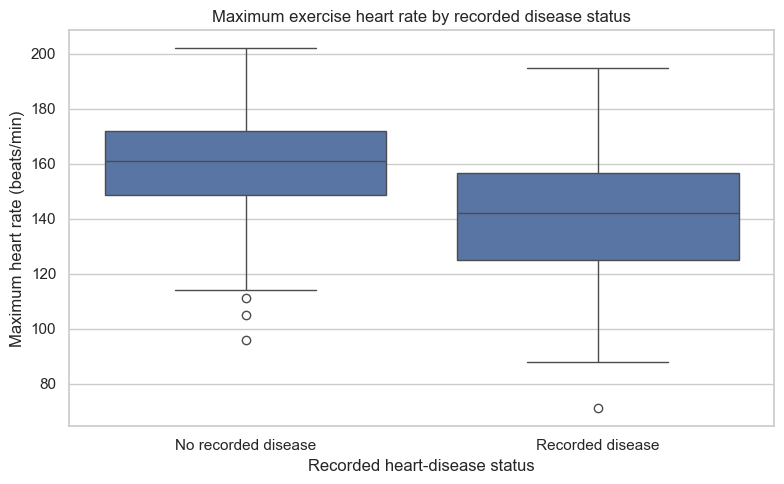

Reading guide: Compare the group medians, IQRs, and unusually high or low values. A box plot alone does not establish statistical significance.


In [6]:
fig,ax=plt.subplots(figsize=(8,5))
sns.boxplot(data=analysis,x="heart_label",y="thalach",ax=ax)
ax.set(title="Maximum exercise heart rate by recorded disease status",xlabel="Recorded heart-disease status",ylabel="Maximum heart rate (beats/min)")
fig.tight_layout();fig.savefig(CHARTS/"01_heart_rate_boxplot.png",dpi=170);plt.show()
print("Reading guide: Compare the group medians, IQRs, and unusually high or low values. A box plot alone does not establish statistical significance.")

**Figure 1 interpretation — group comparison.** The group without recorded disease has a higher central maximum exercise heart rate than the group with recorded disease. Both boxplots show considerable within-group variation and overlap, so maximum heart rate alone cannot classify individual patients. The single low-end IQR flag is retained rather than discarded without clinical justification.

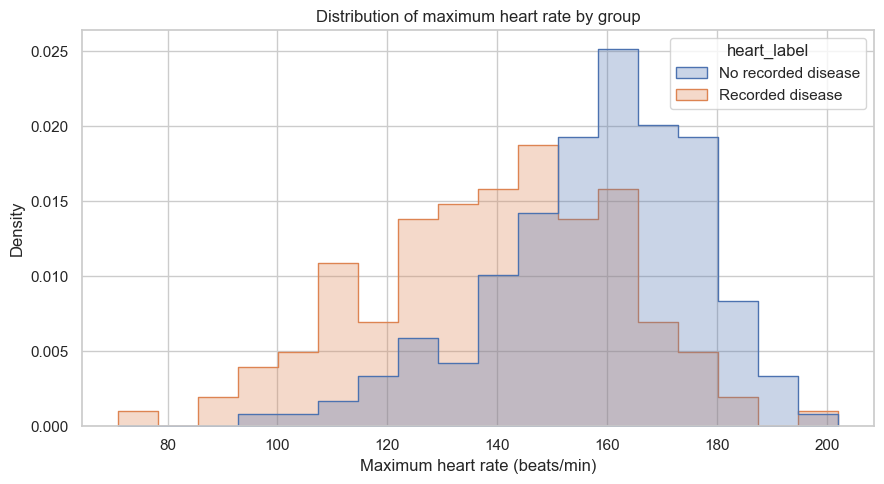

Reading guide: Note overlap and shape; density scaling avoids mistaking different group sizes for different distribution shapes.


In [7]:
fig,ax=plt.subplots(figsize=(9,5))
sns.histplot(data=analysis,x="thalach",hue="heart_label",bins=18,stat="density",common_norm=False,element="step",alpha=.30,ax=ax)
ax.set(title="Distribution of maximum heart rate by group",xlabel="Maximum heart rate (beats/min)",ylabel="Density")
fig.tight_layout();fig.savefig(CHARTS/"02_heart_rate_distributions.png",dpi=170);plt.show()
print("Reading guide: Note overlap and shape; density scaling avoids mistaking different group sizes for different distribution shapes.")

**Figure 2 interpretation — distribution shape.** The distributions overlap across a wide range of heart rates, but the no-recorded-disease group is shifted toward higher values. This visual pattern motivates a formal two-group mean comparison; the histogram by itself cannot establish a statistically significant or causal effect.

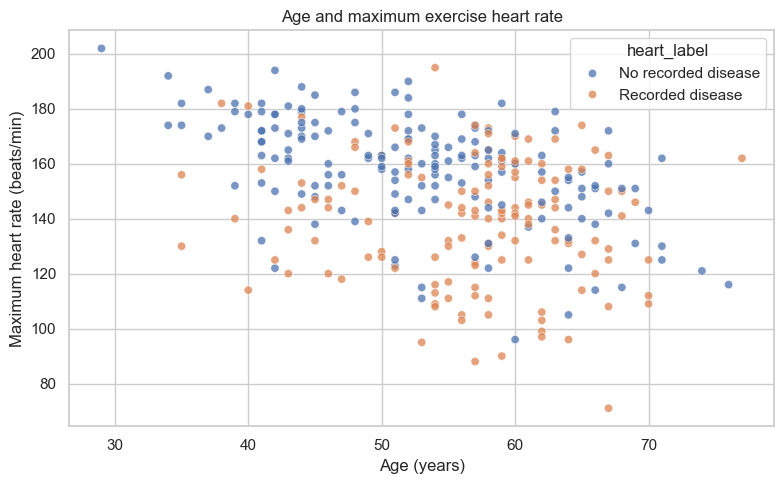

Reading guide: Age may be associated with heart rate and disease status, so an unadjusted group comparison may be confounded.


In [8]:
fig,ax=plt.subplots(figsize=(8,5))
sns.scatterplot(data=analysis,x="age",y="thalach",hue="heart_label",alpha=.75,ax=ax)
ax.set(title="Age and maximum exercise heart rate",xlabel="Age (years)",ylabel="Maximum heart rate (beats/min)")
fig.tight_layout();fig.savefig(CHARTS/"03_age_heart_rate.png",dpi=170);plt.show()
print("Reading guide: Age may be associated with heart rate and disease status, so an unadjusted group comparison may be confounded.")

**Figure 3 interpretation — age as a potential confounder.** Age and maximum heart rate may vary together, and age distributions may differ between the two disease groups. The scatterplot provides context for why an unadjusted difference in means must not be interpreted as an age-independent or causal association.

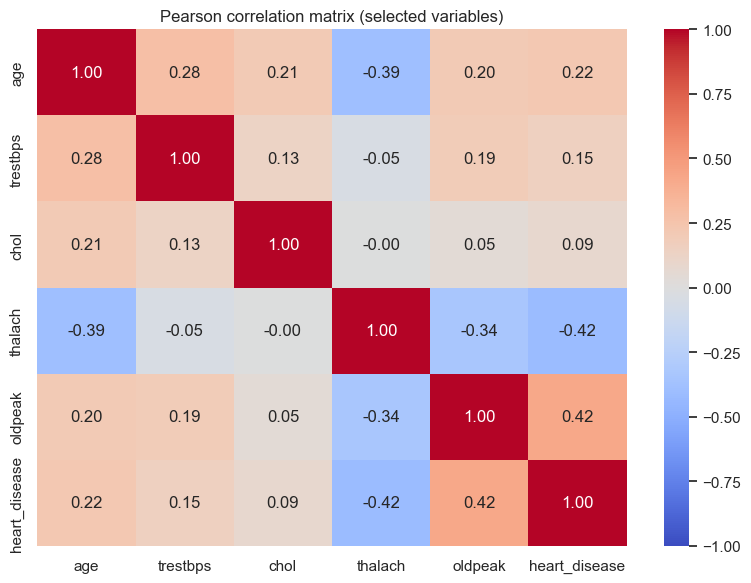

Caution: Correlation is not causation; binary-group correlation is a descriptive association, not a diagnostic result.


In [9]:
features=["age","trestbps","chol","thalach","oldpeak","heart_disease"]
cor = analysis[features].corr(method="pearson")
fig,ax=plt.subplots(figsize=(8,6))
sns.heatmap(cor,annot=True,fmt=".2f",cmap="coolwarm",vmin=-1,vmax=1,center=0,ax=ax)
ax.set_title("Pearson correlation matrix (selected variables)")
fig.tight_layout();fig.savefig(CHARTS/"04_correlation_heatmap.png",dpi=170);plt.show()
print("Caution: Correlation is not causation; binary-group correlation is a descriptive association, not a diagnostic result.")

**Figure 4 interpretation — correlation heatmap.** Correlations summarize pairwise linear relationships among the selected numeric measurements. `heart_disease` is binary, so its Pearson correlations should be treated as descriptive associations, not causal effects or measures of clinical predictive usefulness. The matrix also does not adjust for other variables.

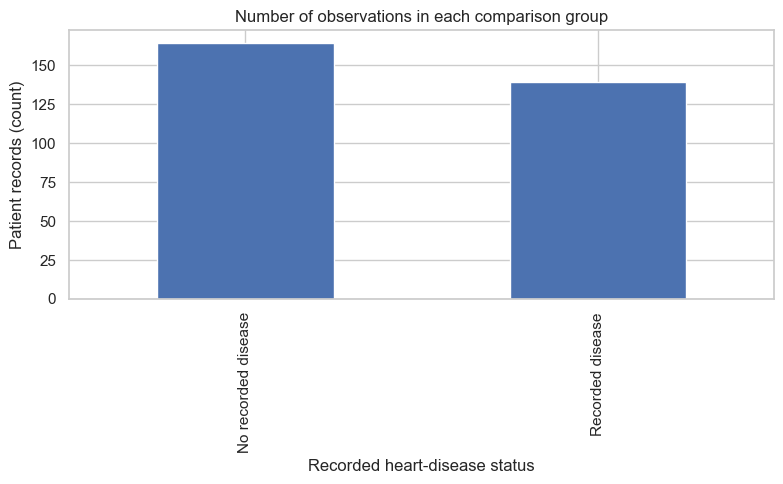

Reading guide: Unequal sample sizes can affect uncertainty and motivate Welch's unequal-variance test.


In [10]:
fig,ax=plt.subplots(figsize=(8,5))
analysis["heart_label"].value_counts().reindex(["No recorded disease","Recorded disease"]).plot.bar(ax=ax)
ax.set(title="Number of observations in each comparison group",xlabel="Recorded heart-disease status",ylabel="Patient records (count)")
fig.tight_layout();fig.savefig(CHARTS/"05_group_counts.png",dpi=170);plt.show()
print("Reading guide: Unequal sample sizes can affect uncertainty and motivate Welch's unequal-variance test.")

**Figure 5 interpretation — group sizes.** The sample includes 164 records without recorded disease and 139 with recorded disease. Both groups are sufficiently represented for a two-group exploratory comparison, but the clinical sample is not a random survey of the United States.

## 8 | Statistical hypothesis test (20 points)
**Primary test:** Welch's independent-samples t-test (two-sided), which does not assume equal variances. The outcome is numerical (`thalach`); the grouping variable is binary (`num==0` versus `num>0`). Report group means, difference, p-value, 95% confidence interval, and Cohen's d as a descriptive standardized effect size.

**Assumptions/limits:** Independent observations are assumed but cannot be fully verified from these records. Sample distributions can be inspected above. The test does not adjust for age or other confounders; p < .05 is not proof of causality or clinical usefulness.

In [11]:
a=analysis.loc[analysis["heart_disease"]==0,"thalach"].to_numpy()
b=analysis.loc[analysis["heart_disease"]==1,"thalach"].to_numpy()
res=stats.ttest_ind(a,b,equal_var=False)
difference=a.mean()-b.mean()
se=np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))
df_w=(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))**2/((a.var(ddof=1)/len(a))**2/(len(a)-1)+(b.var(ddof=1)/len(b))**2/(len(b)-1))
ci=stats.t.interval(.95,df=df_w,loc=difference,scale=se)
pooled=np.sqrt(((len(a)-1)*a.var(ddof=1)+(len(b)-1)*b.var(ddof=1))/(len(a)+len(b)-2))
d=difference/pooled
print(f"No recorded disease: n={len(a)}, mean={a.mean():.2f} bpm")
print(f"Recorded disease: n={len(b)}, mean={b.mean():.2f} bpm")
print(f"Difference (no disease minus disease): {difference:.2f} bpm")
print(f"Welch t={res.statistic:.3f}, df={df_w:.1f}, two-sided p={res.pvalue:.5g}")
print(f"95% CI for mean difference: [{ci[0]:.2f}, {ci[1]:.2f}] bpm")
print(f"Cohen's d (unadjusted): {d:.3f}")
print("Decision at alpha=.05:","Reject H0 (statistical evidence of different group means)." if res.pvalue<.05 else "Do not reject H0 (insufficient evidence of different means).")
assert np.isfinite(res.pvalue) and np.isfinite(ci).all()

No recorded disease: n=164, mean=158.38 bpm
Recorded disease: n=139, mean=139.26 bpm
Difference (no disease minus disease): 19.12 bpm
Welch t=7.858, df=272.3, two-sided p=9.1062e-14
95% CI for mean difference: [14.33, 23.91] bpm
Cohen's d (unadjusted): 0.918
Decision at alpha=.05: Reject H0 (statistical evidence of different group means).


### Sensitivity check: rank-based comparison
A two-sided Mann–Whitney U test provides a useful nonparametric comparison when distributions may not be normal. It tests differences in relative ranks/distributions and is **not automatically a test of median differences**. Treat it as a supplementary check, not a replacement for the primary predeclared Welch test.

In [12]:
mw=stats.mannwhitneyu(a,b,alternative="two-sided")
print(f"Mann–Whitney U={mw.statistic:.1f}, two-sided p={mw.pvalue:.5g}")
print("Pearson age–heart-rate correlation (overall):")
r,pv=stats.pearsonr(analysis["age"],analysis["thalach"])
print(f"r={r:.3f}, p={pv:.5g}")
print("Note: Multiple exploratory tests are descriptive and should not be interpreted as independent confirmatory findings.")

Mann–Whitney U=16989.5, two-sided p=1.861e-13
Pearson age–heart-rate correlation (overall):
r=-0.394, p=1.1093e-12
Note: Multiple exploratory tests are descriptive and should not be interpreted as independent confirmatory findings.


## 9 | Optional extra credit (+5 points): transparent classification baseline
**Task:** Predict binary recorded heart-disease status from selected clinical features. This is **exploratory**, not a medical screening tool.

To avoid leakage: split into training/test sets first; fit imputers and scaling on training data only using a pipeline; never include the original `num` or derived `heart_label` as predictors. Report baseline accuracy, test accuracy, precision, recall, confusion matrix, false positives, and false negatives. **A model score does not imply clinical reliability.**

Training rows: 227 | Held-out test rows: 76
Majority-class baseline accuracy: 0.539
Model test accuracy: 0.868; precision: 0.838; recall: 0.886
False positives: 6; false negatives: 4
              precision    recall  f1-score   support

           0       0.90      0.85      0.88        41
           1       0.84      0.89      0.86        35

    accuracy                           0.87        76
   macro avg       0.87      0.87      0.87        76
weighted avg       0.87      0.87      0.87        76



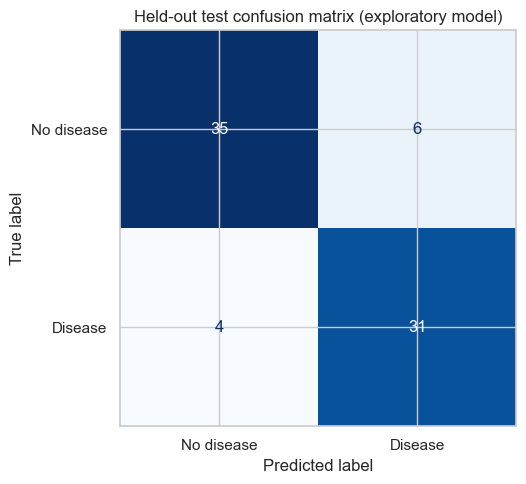

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix,classification_report,ConfusionMatrixDisplay

predictors=["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal"]
model_df=df.dropna(subset=["heart_disease"]).copy()
X=model_df[predictors];y=model_df["heart_disease"].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,stratify=y,random_state=42)
model=Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler()),("classifier",LogisticRegression(max_iter=2000,random_state=42))])
model.fit(X_train,y_train)
pred=model.predict(X_test)
baseline=DummyClassifier(strategy="most_frequent").fit(X_train,y_train)
cm=confusion_matrix(y_test,pred,labels=[0,1]);tn,fp,fn,tp=cm.ravel()
print("Training rows:",len(X_train),"| Held-out test rows:",len(X_test))
print(f"Majority-class baseline accuracy: {accuracy_score(y_test,baseline.predict(X_test)):.3f}")
print(f"Model test accuracy: {accuracy_score(y_test,pred):.3f}; precision: {precision_score(y_test,pred,zero_division=0):.3f}; recall: {recall_score(y_test,pred,zero_division=0):.3f}")
print(f"False positives: {fp}; false negatives: {fn}")
print(classification_report(y_test,pred,zero_division=0))
fig,ax=plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay(cm,display_labels=["No disease","Disease"]).plot(ax=ax,cmap="Blues",colorbar=False)
ax.set_title("Held-out test confusion matrix (exploratory model)")
fig.tight_layout();fig.savefig(CHARTS/"06_optional_model_confusion.png",dpi=170);plt.show()

## 10 | Results, discussion, and conclusion

### Answer to the research question
Among **303 Cleveland clinical records**, the **164** patients without recorded heart disease had a mean maximum exercise heart rate of **158.38 bpm**, versus **139.26 bpm** for the **139** patients with recorded heart disease. The unadjusted mean difference (**no recorded disease minus recorded disease**) was **19.12 bpm**. A two-sided Welch independent-samples t-test yielded **t ≈ 7.858** and **p ≈ 9.11 × 10⁻¹⁴**, with a **95% confidence interval of approximately 14.33 to 23.91 bpm** for the mean difference. Because p < .05, we reject the null hypothesis of equal population group means under the test's assumptions. The estimated standardized difference was **Cohen's d ≈ 0.918**.

### Interpretation and practical meaning
The data support an **association** between recorded disease status and lower observed maximum exercise heart rate in this historical sample. The confidence interval describes uncertainty about the **unadjusted mean difference**, not the probability of disease for an individual. The overlapping group distributions show that patients cannot be reliably categorized using heart rate alone. A statistically significant difference does **not** establish a clinically useful screening threshold, a causal relationship, or a diagnosis.

### Data-quality decisions and consequences
The original dataset contains **six missing values** in `ca` (four) and `thal` (two). Neither variable is required for the primary comparison, so **all 303 rows were retained**; imputing unrelated measurements or discarding otherwise usable observations would add unnecessary assumptions or lose data. The dataset has **zero exact duplicate rows**, so none were removed. An IQR screen flagged **one** unusual maximum-heart-rate observation, but it was retained because an unusual clinical measurement is not automatically an error. Numeric conversion and coding/range assertions help catch mismatches; the original CSV remains unchanged. In the optional predictive model, missing predictors are filled with medians **learned only from the training split** to prevent information leakage.

### Assumptions, sensitivity, and confounding
Welch's t-test compares group means without requiring equal population variances. Independence of patient records is assumed but cannot be confirmed from this file; histograms and boxplots permit visual inspection of skew and overlap. The Mann–Whitney U test above provides a rank-based sensitivity check, but it does not estimate the same mean difference and should not be interpreted as an identical hypothesis test. Age, medication, fitness, referral patterns, and other patient characteristics could influence both measured exercise heart rate and recorded disease status. This **unadjusted** analysis does not isolate those influences.

### Optional model — exploratory only
The classification exercise uses a stratified held-out test split, training-only preprocessing, and a majority-class baseline. Its test metrics and confusion matrix should be interpreted as performance on **this one split of a small historical dataset**, not evidence of clinical validity. False-positive and false-negative predictions both matter; no medical decision should be made from this demonstration.

### Limitations and ethics
The Cleveland sample is relatively small, historical, clinical, and not a probability sample of US residents. Disease status is simplified from original `num` codes 0–4 into 0 versus 1–4, which discards severity information. Some clinical variables are incomplete; measurements and diagnostic practices may differ today. Multiple exploratory charts and correlations are descriptive and do not correct for confounding or multiple comparisons. This work is educational and **not medical advice**. Dataset attribution and license information appear in Section 2.

### Final conclusion
**Maximum exercise heart rate was lower on average among patients with recorded heart disease in the Cleveland dataset, with a statistically significant unadjusted mean difference of about 19 bpm.** The evidence is limited to association in this sample; further representative, adjusted, and externally validated research would be needed for broader or clinical conclusions.

**Student-authorship check:** Before submitting, read every interpretation, confirm that it reflects your own understanding, and revise any wording you cannot explain. Disclose AI assistance accurately in the repository's prompt log and course-required format.

In [15]:
print("FINAL QUALITY CHECK")
assert len(raw)==303 and raw.shape[1]==14
assert raw.isna().sum().sum()==6
assert raw.duplicated().sum()==0
assert len(analysis)==303
assert (CHARTS/"01_heart_rate_boxplot.png").exists()
assert (CHARTS/"06_optional_model_confusion.png").exists()
print("Passed: schema, missingness, duplicates, analysis sample, exported figures")
print("Charts saved:",len(list(CHARTS.glob("*.png"))))


FINAL QUALITY CHECK
Passed: schema, missingness, duplicates, analysis sample, exported figures
Charts saved: 6


## 11 | Reproducibility, citation, and submission checklist

**Reproduce:** Keep this notebook in the project root with `data/cleveland_heart_disease.csv`; install `requirements.txt`, select a Python kernel, then choose **Restart & Run All**. The notebook writes figures into `charts/` and a cleaning audit to `cleaning_log.csv`. If running from a `notebooks/` subfolder, use the supplied project folder structure or adjust the dataset path as documented in the setup cell.

**Dataset citation:** Janosi, A., Steinbrunn, W., Pfisterer, M., and Detrano, R. *Heart Disease*. UCI Machine Learning Repository. DOI: 10.24432/C52P4X. Cleveland processed subset; source and license: https://archive.ics.uci.edu/dataset/45/heart+disease (CC BY 4.0).





In [16]:
print("SUBMISSION SUMMARY")
print(f"Rows: {len(raw)} | Missing source values: {int(raw.isna().sum().sum())} | Exact duplicates: {int(raw.duplicated().sum())}")
print(f"Group means: {a.mean():.2f} vs {b.mean():.2f} bpm | Difference: {difference:.2f} bpm")
print(f"95% CI: ({ci[0]:.2f}, {ci[1]:.2f}) | Welch p: {res.pvalue:.3g}")
print(f"Saved figures: {len(list(CHARTS.glob('*.png')))}")
assert len(list(CHARTS.glob('*.png'))) >= 6
print("Notebook execution and output checks passed.")

SUBMISSION SUMMARY
Rows: 303 | Missing source values: 6 | Exact duplicates: 0
Group means: 158.38 vs 139.26 bpm | Difference: 19.12 bpm
95% CI: (14.33, 23.91) | Welch p: 9.11e-14
Saved figures: 6
Notebook execution and output checks passed.
